# LEVEL 2

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
dataset=pd.read_csv("Dataset .csv")
dataset.head(5)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
dataset['Restaurant ID']= dataset['Restaurant ID'].astype(str)
dataset['Country Code']= dataset['Country Code'].astype("category")

In [4]:
dataset.describe()

,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


# TASK1
## Task: Restaurant Ratings

## Ques-- Analyze the distribution of aggregate ratings and determine the most common rating range.

In [5]:
dataset['Aggregate rating'].describe()

count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64

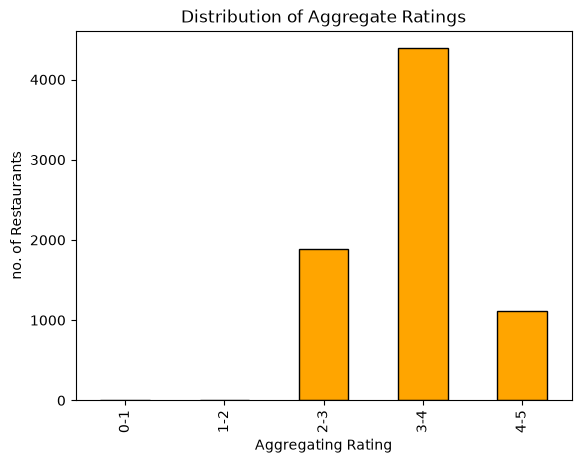

In [6]:
bins = [0, 1, 2, 3, 4, 5]
labels = ["0-1", "1-2", "2-3", "3-4", "4-5"]
rated = dataset[dataset["Aggregate rating"] > 0]
rating_range = pd.cut(rated["Aggregate rating"], bins=bins, labels=labels)
range_counts = rating_range.value_counts().sort_index()
range_counts.plot(kind="bar", color="orange", edgecolor="black")
plt.title("Distribution of Aggregate Ratings")
plt.xlabel("Aggregating Rating")
plt.ylabel("no. of Restaurants")
plt.show()

## Ques-- Calculate the average number of votes received by restaurants.

In [7]:
avg_votes = dataset["Votes"].mean()
print(round(avg_votes, 2))

156.91


# TASK2
## Task: Cuisine Combination

## Ques-- Identify the most common combinations of cuisines in the dataset.

In [8]:
top_combinations = dataset["Cuisines"].value_counts().head(5)
top_combinations

Cuisines
North Indian             936
North Indian, Chinese    511
Chinese                  354
Fast Food                354
North Indian, Mughlai    334
Name: count, dtype: int64

## Determine if certain cuisine combinations tend to have higher ratings.

In [9]:
rated = dataset[dataset["Aggregate rating"] > 0]
cuisine_ratings = rated.groupby("Cuisines")["Aggregate rating"].agg(["mean", "count"]).round(2)
cuisine_ratings = cuisine_ratings[cuisine_ratings["count"] >= 10]
cuisine_ratings = cuisine_ratings.sort_values("mean", ascending=False)
cuisine_ratings

,mean,count
Cuisines,,
Modern Indian,4.35,11
Indian,4.25,18
Seafood,4.11,14
Thai,4.10,16
"American, Burger",4.08,13
...,...,...
"North Indian, South Indian",3.02,18
"North Indian, South Indian, Chinese, Fast Food",3.00,11
"American, Fast Food, Salad, Healthy Food",3.00,60


# TASK3
## Task: Geographic Analysis

## Ques-- Plot the locations of restaurants on a map using longitude and latitude coordinates.

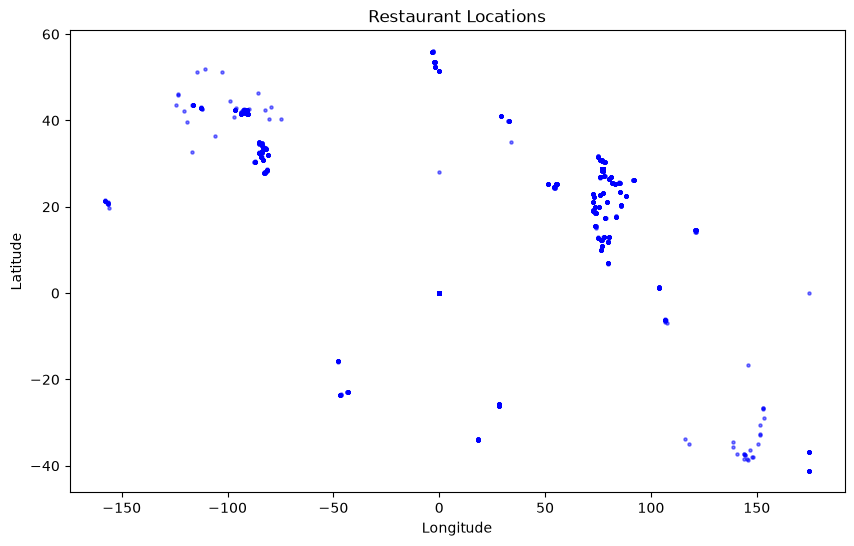

In [10]:
plt.figure(figsize=(10,6))
plt.scatter(dataset["Longitude"], dataset["Latitude"], s=5, alpha=0.5, color="blue")
plt.title("Restaurant Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## Ques-- Identify any patterns or clusters of restaurants in specific areas.

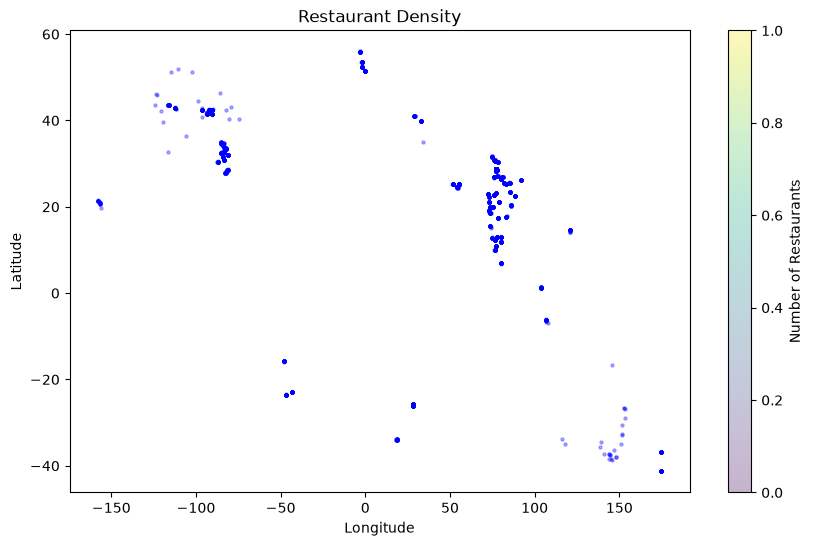

In [11]:

clean = dataset[(dataset["Longitude"] != 0) & (dataset["Latitude"] != 0)]

plt.figure(figsize=(10, 6))
plt.scatter(clean["Longitude"], clean["Latitude"], s=5, alpha=0.3, color="blue")
plt.colorbar(label="Number of Restaurants")
plt.title("Restaurant Density")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# TASK4
## Task: Restaurant Chains

## Ques-- Identify if there are any restaurant chains present in the dataset.

In [12]:
chain_counts = dataset["Restaurant Name"].value_counts()
chains = chain_counts[chain_counts > 1]
print(chains.head(10))
print(f"\nNumber of restaurant chains: {len(chains)}")

Restaurant Name
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Name: count, dtype: int64

Number of restaurant chains: 734


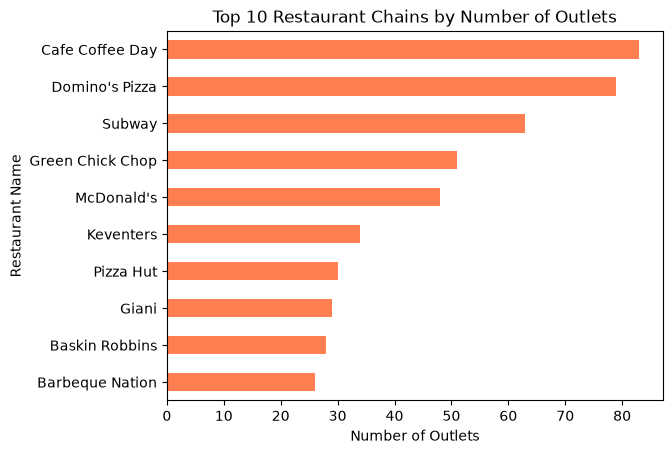

In [13]:
chains.head(10).plot(kind="barh", color="coral")
plt.title("Top 10 Restaurant Chains by Number of Outlets")
plt.xlabel("Number of Outlets")
plt.gca().invert_yaxis()
plt.show()

## Ques-- Analyze the ratings and popularity of different restaurant chains.

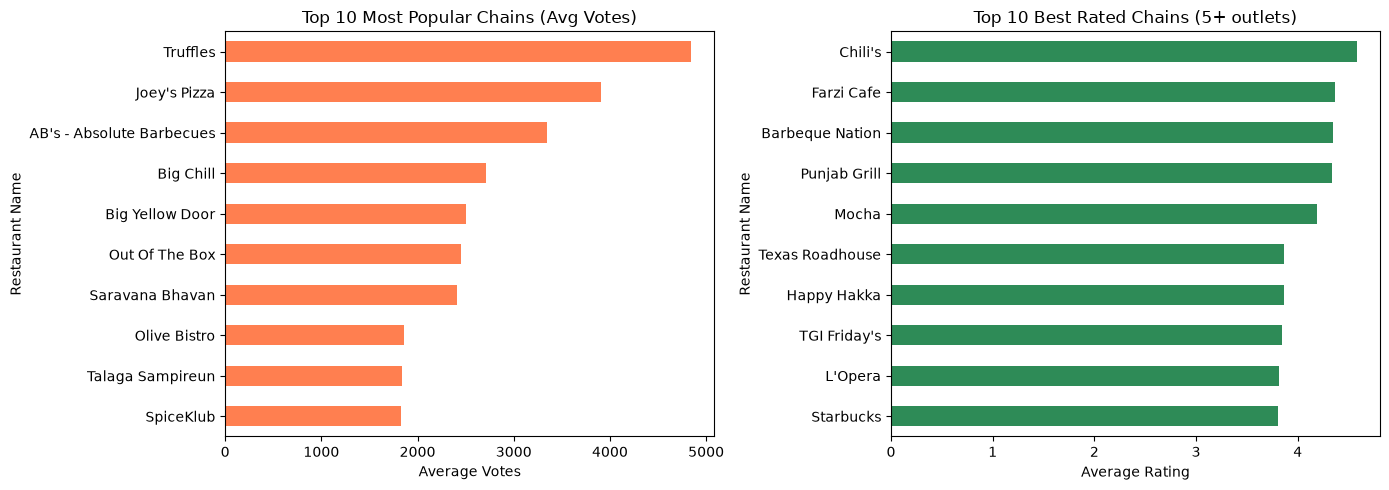

In [14]:

counts = dataset["Restaurant Name"].value_counts()
chains = dataset[dataset["Restaurant Name"].isin(counts[counts > 1].index)]

# Ratings and popularity per chain
chain_stats = chains.groupby("Restaurant Name").agg(
    Outlets=("Restaurant Name", "count"),
    Avg_Rating=("Aggregate rating", "mean"),
    Avg_Votes=("Votes", "mean")
).round(2)
# print(chain_stats.sort_values("Avg_Votes", ascending=False).head(10))

# Top 10 most popular chains (by average votes)
popular = chain_stats.sort_values("Avg_Votes", ascending=False).head(10)

# Top 10 best rated chains (at least 5 outlets)
best_rated = chain_stats[chain_stats["Outlets"] >= 5].sort_values("Avg_Rating", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Popularity
popular["Avg_Votes"].plot(kind="barh", color="coral", ax=axes[0])
axes[0].set_title("Top 10 Most Popular Chains (Avg Votes)")
axes[0].set_xlabel("Average Votes")
axes[0].invert_yaxis()

# Chart 2: Ratings
best_rated["Avg_Rating"].plot(kind="barh", color="seagreen", ax=axes[1])
axes[1].set_title("Top 10 Best Rated Chains (5+ outlets)")
axes[1].set_xlabel("Average Rating")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()